# WP Reference Database Inventory
Inventories `wp.fna` (whole-plasmid nucleotide reference) to show:
- sequence counts and total bp per species
- which replicons are present across strains
- assembly length / contiguity distributions
- over-represented species

Run from project root: `notes/db_inventory.ipynb`

In [11]:
# Install visualization libraries if not present (only needed once per kernel)
import subprocess, sys
try:
    import matplotlib
except ImportError:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'matplotlib', 'seaborn'])
    import matplotlib
try:
    import seaborn
except ImportError:
    pass

In [12]:
import re
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.patches as mpatches
import numpy as np
import pandas as pd
import seaborn as sns
from Bio import SeqIO

# ── configuration — works whether you launch Jupyter from project root or notes/ ──
# Climb up from the notebook file to find the repo root (contains src/)
NOTEBOOK_DIR = Path('__file__').resolve().parent if '__file__' in dir() else Path.cwd()
ROOT = next(
    (p for p in [NOTEBOOK_DIR, NOTEBOOK_DIR.parent] if (p / 'src').is_dir()),
    NOTEBOOK_DIR,
)
WP_FASTA      = ROOT / 'src/plasmid_caller/db/ref_seqs/wp.fna'
PF32_FASTA    = ROOT / 'src/plasmid_caller/db/ref_seqs/pf32.faa'
MANIFEST      = ROOT / 'new_db/assemblies.tsv'
FIGURES_DIR   = ROOT / 'notes'

assert WP_FASTA.exists(), f'Not found: {WP_FASTA}'

plt.rcParams.update({
    'figure.dpi': 120,
    'font.size': 10,
    'axes.spines.top': False,
    'axes.spines.right': False,
})
print(f'Project root : {ROOT}')
print(f'WP FASTA     : {WP_FASTA}')

Project root : /home/mf019/plasmid_caller
WP FASTA     : /home/mf019/plasmid_caller/src/plasmid_caller/db/ref_seqs/wp.fna


## 1. Parse FASTA headers
Extracts `species`, `strain`, and `replicon` from the NCBI description line.

The headers have two naming generations and several strain-prefix formats,
so we look for canonical replicon tokens (`cp`/`lp`/`p` + digits) embedded
inside whatever prefix the depositor used.

In [13]:
# ── canonical replicon sizes used for sorting ────────────────────────────────
REPLICON_SORT_KEY = {
    'chromosome': 0,
    'cp9': 10, 'cp26': 20,
    'cp32-1': 31, 'cp32-2': 32, 'cp32-3': 33, 'cp32-4': 34, 'cp32-5': 35,
    'cp32-6': 36, 'cp32-7': 37, 'cp32-8': 38, 'cp32-9': 39,
    'cp32-10': 40, 'cp32-11': 41, 'cp32-12': 42, 'cp32-13': 43, 'cp32-14': 44,
    'lp17': 50, 'lp21': 51, 'lp25': 52,
    'lp28-1': 61, 'lp28-2': 62, 'lp28-3': 63, 'lp28-4': 64, 'lp28-5': 65,
    'lp28-6': 66, 'lp28-7': 67, 'lp28-8': 68, 'lp28-9': 69,
    'lp28-10': 70, 'lp28-11': 71, 'lp28-12': 72, 'lp28-13': 73, 'lp28-14': 74,
    'lp32-7': 80, 'lp32-10': 81,
    'lp36': 90, 'lp38': 91, 'lp54': 92, 'lp56': 93,
}

# Borreli(?:ella?|a) matches both "Borrelia" (pre-2018) and "Borreliella" (post-2018).
# Borreli[ae]lla? only matches Borreliella — it requires 'll' after the character class,
# which Borrelia (ending '…i-a') never supplies.
_GENUS_PAT = r'Borreli(?:ella?|a)'


def _extract_replicon(plasmid_field: str) -> str:
    raw = re.sub(
        r',?\s*(?:complete|partial|whole)\s+(?:sequence|genome).*',
        '', plasmid_field, flags=re.IGNORECASE,
    ).strip().lower()
    cp_hits = re.findall(r'(?:^|[^l])p\d', raw)
    lp_hits = re.findall(r'lp\d', raw)
    if cp_hits and lp_hits:
        return 'hybrid'
    raw = re.sub(r'(cp|lp)(\d+)_(\d+)', r'\1\2-\3', raw)
    m = re.search(r'(?:^|[_\s])((?:cp|lp)\d+(?:-\d+)?)\+\d', raw)
    if m:
        return m.group(1) + '+fused'
    m = re.search(r'(?:^|[_\s])((?:cp|lp)\d+(?:-\d+)?)(?:-\d+)?(?:[_\s,]|$)', raw)
    if m:
        return m.group(1).lower()
    m = re.search(r'(?:^|[_\s])(p(\d+(?:-\d+)?))(?:-\d+)?(?:[_\s,]|$)', raw)
    if m:
        num = m.group(2)
        base = num.split('-')[0]
        linear_bases = {'17', '21', '25', '28', '36', '38', '54', '56'}
        if base == '32':
            return f'cp{num}'
        prefix = 'lp' if base in linear_bases else 'cp'
        return f'{prefix}{num}'
    return f'other:{raw[:30]}'


def _extract_strain(desc: str) -> str:
    # Modern format: '... strain NE_5261 ...'
    m = re.search(r'\bstrain\s+(\S+)', desc, re.IGNORECASE)
    if m:
        return m.group(1).rstrip(',')
    # Old format: 'Borrelia burgdorferi JD1, complete genome' (no "strain" keyword)
    # re.search (not re.match) because desc starts with the accession ID
    m = re.search(
        _GENUS_PAT + r'\s+\S+(?:\s+sensu\s+stricto)?\s+(\S+?)[,\s]',
        desc, re.IGNORECASE,
    )
    if m:
        candidate = m.group(1)
        if not re.match(r'(?:cp|lp|chromosome|plasmid|complete)', candidate, re.I):
            return candidate
    return 'unknown'


def _extract_species(desc: str) -> str:
    # re.search (not re.match) because desc starts with the accession ID
    m = re.search(
        r'(' + _GENUS_PAT + r'\s+\S+(?:\s+sensu\s+stricto)?)',
        desc, re.IGNORECASE,
    )
    if m:
        sp = m.group(1)
        # Normalise to "Borrelia" regardless of which genus spelling the depositor used
        return re.sub(r'^Borreliella\b', 'Borrelia', sp, flags=re.IGNORECASE)
    return 'Unknown'


def parse_wp_fasta(fasta_path: Path) -> pd.DataFrame:
    records = []
    for rec in SeqIO.parse(fasta_path, 'fasta'):
        desc = rec.description  # 'ACCESSION Description text ...'
        species = _extract_species(desc)
        strain  = _extract_strain(desc)
        seq_len = len(rec.seq)
        pm = re.search(r'\bplasmid\s+(.+)', desc, re.IGNORECASE)
        if pm:
            replicon = _extract_replicon(pm.group(1))
        elif re.search(r'\bchromosome\b', desc, re.IGNORECASE):
            replicon = 'chromosome'
        else:
            replicon = 'chromosome'
        records.append({
            'accession': rec.id,
            'description': desc,
            'species': species,
            'strain': strain,
            'replicon': replicon,
            'seq_len': seq_len,
        })
    df = pd.DataFrame(records)
    df['replicon_sort'] = df['replicon'].map(REPLICON_SORT_KEY).fillna(999)
    df['species_short'] = df['species'].str.replace(r'^Borrelia\s+', 'B. ', regex=True)
    return df


df = parse_wp_fasta(WP_FASTA)
print(f'Parsed {len(df):,} sequences across {df["species"].nunique()} species '
      f'and {df["strain"].nunique()} strains')
df.head()

Parsed 1,154 sequences across 23 species and 102 strains


,accession,description,species,strain,replicon,seq_len,replicon_sort,species_short
0,CP124100.1,CP124100.1 Borreliella burgdorferi strain NE_5...,Borrelia burgdorferi,NE_5261,chromosome,910422,0.0,B. burgdorferi
1,CP124098.1,CP124098.1 Borreliella burgdorferi strain NE_5...,Borrelia burgdorferi,NE_5261,lp17,17222,50.0,B. burgdorferi
2,CP124097.1,CP124097.1 Borreliella burgdorferi strain NE_5...,Borrelia burgdorferi,NE_5261,cp26,26454,20.0,B. burgdorferi
3,CP124099.1,CP124099.1 Borreliella burgdorferi strain NE_5...,Borrelia burgdorferi,NE_5261,lp54,53730,92.0,B. burgdorferi
4,CP019844.1,CP019844.1 Borreliella burgdorferi strain PAli...,Borrelia burgdorferi,PAli,chromosome,909921,0.0,B. burgdorferi


In [14]:
# Quick-look at any replicons that failed to canonicalize
other = df[df['replicon'].str.startswith('other:', na=False)]
if other.empty:
    print('All replicons canonicalized successfully.')
else:
    print(f'{len(other)} unrecognized replicon names:')
    print(other[['accession', 'species', 'strain', 'replicon', 'description']].to_string(index=False))

All replicons canonicalized successfully.


## 2. Species-level summary

In [15]:
per_species = (
    df.groupby('species_short')
    .agg(
        n_sequences=('accession', 'count'),
        n_strains=('strain', 'nunique'),
        total_mbp=('seq_len', lambda x: x.sum() / 1e6),
        median_seq_len_kb=('seq_len', lambda x: x.median() / 1e3),
        n_replicon_types=('replicon', 'nunique'),
    )
    .sort_values('n_sequences', ascending=False)
    .reset_index()
)
per_species['seqs_per_strain'] = (per_species['n_sequences'] / per_species['n_strains']).round(1)
print(per_species.to_string(index=False))

    species_short  n_sequences  n_strains  total_mbp  median_seq_len_kb  n_replicon_types  seqs_per_strain
   B. burgdorferi          405         31  35.976931            29.7580                45             13.1
   B. bavariensis          256         18  22.637117            26.9880                21             14.2
       B. tanukii           58          4   5.231298            30.2125                23             14.5
       B. afzelii           48          4   4.949783            30.0325                21             12.0
  B. carolinensis           38          4   4.679026            30.6650                20              9.5
   B. yangtzensis           38          3   3.839102            30.4450                27             12.7
    B. valaisiana           35          3   3.843992            30.0480                19             11.7
      B. japonica           34          2   2.887992            30.7175                23             17.0
         B. turdi           27       

## 3. Figure 1 — Sequences per species (over-representation)

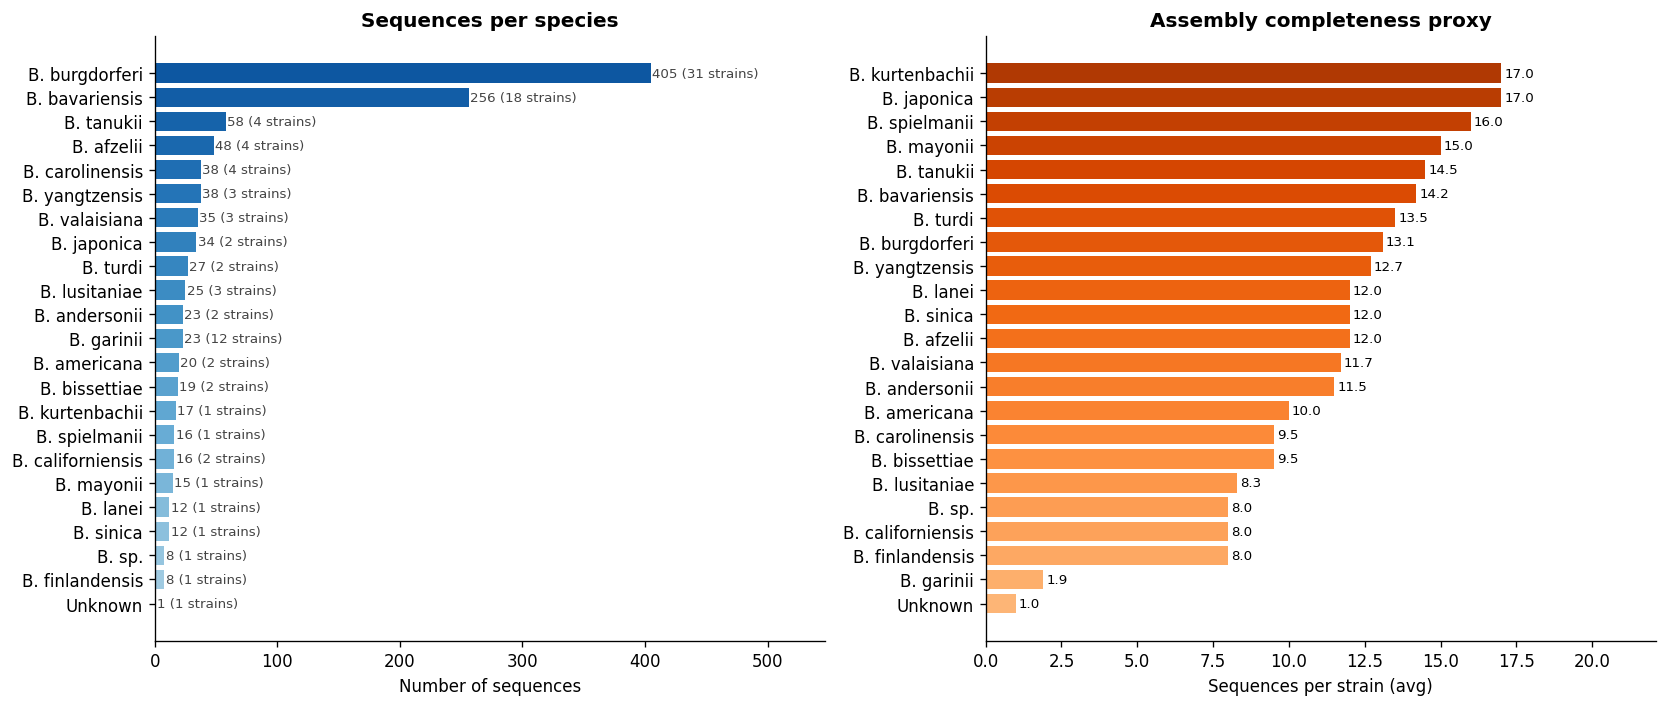

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

ax = axes[0]
sp = per_species.sort_values('n_sequences')
colors = plt.cm.Blues(np.linspace(0.35, 0.85, len(sp)))
ax.barh(sp['species_short'], sp['n_sequences'], color=colors)
ax.set_xlabel('Number of sequences')
ax.set_title('Sequences per species', fontweight='bold')
for i, row in sp.iterrows():
    idx = sp.index.get_loc(i)
    ax.text(row['n_sequences'] + 1, idx,
            f"{int(row['n_sequences'])} ({int(row['n_strains'])} strains)",
            va='center', fontsize=8, color='#444')
ax.set_xlim(0, sp['n_sequences'].max() * 1.35)

ax2 = axes[1]
sp2 = per_species.sort_values('seqs_per_strain')
colors2 = plt.cm.Oranges(np.linspace(0.35, 0.85, len(sp2)))
ax2.barh(sp2['species_short'], sp2['seqs_per_strain'], color=colors2)
ax2.set_xlabel('Sequences per strain (avg)')
ax2.set_title('Assembly completeness proxy', fontweight='bold')
for i, row in sp2.iterrows():
    idx = sp2.index.get_loc(i)
    ax2.text(row['seqs_per_strain'] + 0.1, idx,
             f"{row['seqs_per_strain']:.1f}", va='center', fontsize=8)
ax2.set_xlim(0, sp2['seqs_per_strain'].max() * 1.3)

plt.tight_layout()
plt.savefig(FIGURES_DIR / 'fig1_seqs_per_species.png', bbox_inches='tight')
plt.show()

## 4. Figure 2 — Replicon type frequency across the whole DB

/tmp/ipykernel_3168/2477767673.py:23: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(replicon_counts['replicon'], rotation=45, ha='right', fontsize=8)


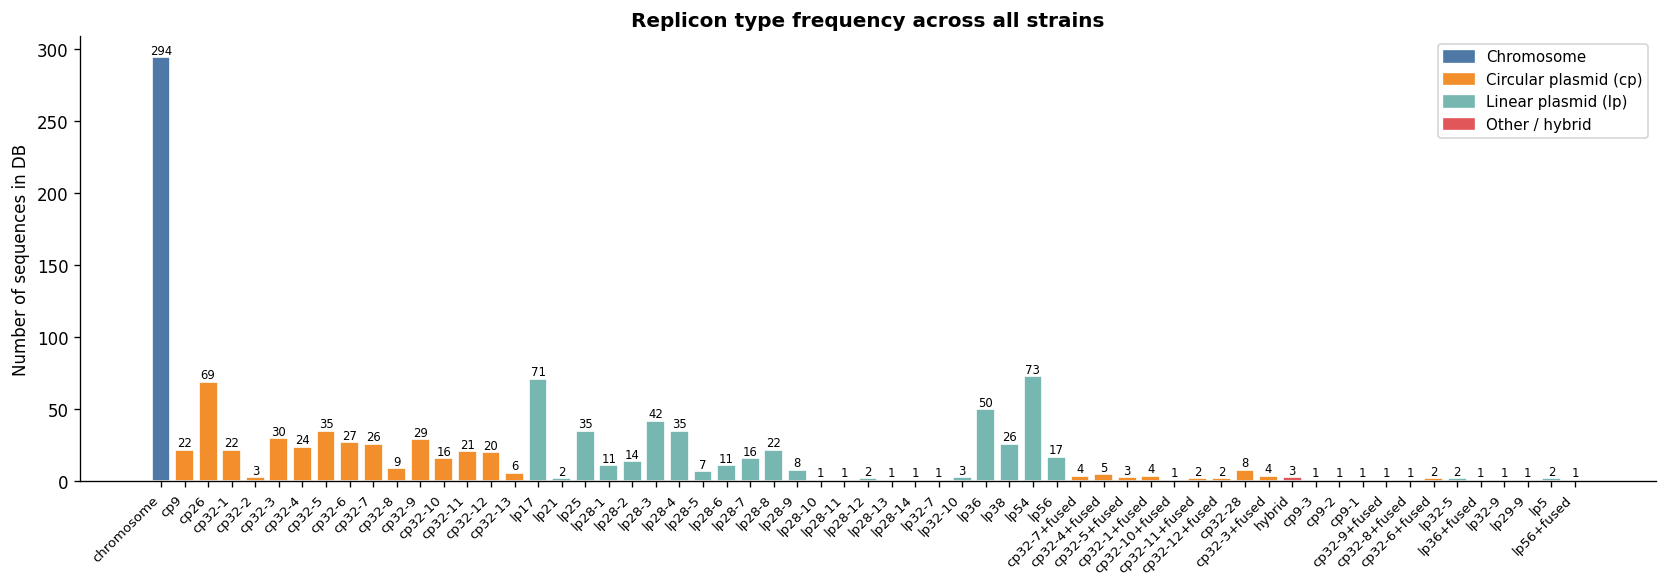

In [17]:
replicon_counts = (
    df.groupby('replicon')
    .agg(n=('accession', 'count'), sort_key=('replicon_sort', 'first'))
    .sort_values('sort_key')
    .reset_index()
)

fig, ax = plt.subplots(figsize=(14, 5))

def _replicon_colour(name: str) -> str:
    if name == 'chromosome': return '#4e79a7'
    if name.startswith('cp'): return '#f28e2b'
    if name.startswith('lp'): return '#76b7b2'
    return '#e15759'

bar_colors = [_replicon_colour(r) for r in replicon_counts['replicon']]
bars = ax.bar(replicon_counts['replicon'], replicon_counts['n'], color=bar_colors, edgecolor='white')
for bar, n in zip(bars, replicon_counts['n']):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.3,
            str(n), ha='center', va='bottom', fontsize=7)
ax.set_ylabel('Number of sequences in DB')
ax.set_title('Replicon type frequency across all strains', fontweight='bold')
ax.set_xticklabels(replicon_counts['replicon'], rotation=45, ha='right', fontsize=8)
ax.legend(handles=[
    mpatches.Patch(color='#4e79a7', label='Chromosome'),
    mpatches.Patch(color='#f28e2b', label='Circular plasmid (cp)'),
    mpatches.Patch(color='#76b7b2', label='Linear plasmid (lp)'),
    mpatches.Patch(color='#e15759', label='Other / hybrid'),
], loc='upper right', fontsize=9)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'fig2_replicon_freq.png', bbox_inches='tight')
plt.show()

## 5. Figure 3 — Strain × replicon presence/absence heatmap

Each cell shows **sequence length (kb)** when present (white = absent).
Strains are sorted by species then by total sequence count (most complete first).

In [ ]:
def replicon_heatmap(
    df: pd.DataFrame,
    species_filter: list | None = None,
    min_strains: int = 2,
    figsize: tuple = (22, 14),
    save_path=None,
):
    sub = df.copy()
    if species_filter:
        sub = sub[sub['species_short'].isin(species_filter)]
    strain_counts = sub.groupby('species_short')['strain'].nunique()
    valid_species = strain_counts[strain_counts >= min_strains].index
    sub = sub[sub['species_short'].isin(valid_species)]
    sub = sub.copy()
    sub['strain_label'] = sub['species_short'] + ' | ' + sub['strain']
    pivot = (
        sub.groupby(['strain_label', 'species_short', 'replicon'])['seq_len']
        .max().reset_index()
    )
    pivot_wide = pivot.pivot_table(
        index=['strain_label', 'species_short'], columns='replicon', values='seq_len',
    )
    col_order = sorted(pivot_wide.columns, key=lambda c: REPLICON_SORT_KEY.get(c, 999))
    pivot_wide = pivot_wide[col_order]
    presence = pivot_wide.notna().sum(axis=1)
    # index=False avoids 'species_short is both index level and column' ambiguity
    sort_df = pivot_wide.index.to_frame(index=False).assign(_presence=presence.values)
    pivot_wide = pivot_wide.loc[
        sort_df.sort_values(['species_short', '_presence'], ascending=[True, False])
               .set_index(['strain_label', 'species_short']).index
    ]
    strain_labels = pivot_wide.index.get_level_values('strain_label')
    species_labels = pivot_wide.index.get_level_values('species_short')
    data_kb = pivot_wide.values / 1000

    cmap = plt.cm.YlGnBu
    norm = mcolors.Normalize(vmin=0, vmax=np.nanpercentile(data_kb[data_kb > 0], 95))
    fig, ax = plt.subplots(figsize=figsize)
    masked = np.ma.masked_invalid(data_kb)
    ax.imshow(masked, aspect='auto', cmap=cmap, norm=norm, interpolation='nearest')
    ax.set_facecolor('white')
    nan_overlay = np.ma.masked_where(~np.isnan(data_kb), np.ones_like(data_kb))
    ax.imshow(nan_overlay, aspect='auto',
              cmap=mcolors.ListedColormap(['#f0f0f0']), vmin=0, vmax=1, interpolation='nearest')
    ax.set_xticks(range(len(col_order)))
    ax.set_xticklabels(col_order, rotation=60, ha='right', fontsize=8)
    ax.set_yticks(range(len(strain_labels)))
    ax.set_yticklabels(strain_labels, fontsize=7)
    prev_sp = None
    for i, sp in enumerate(species_labels):
        if sp != prev_sp and i > 0:
            ax.axhline(i - 0.5, color='black', linewidth=0.8, linestyle='--', alpha=0.4)
        prev_sp = sp
    im = ax.images[0]
    cbar = plt.colorbar(im, ax=ax, fraction=0.015, pad=0.02)
    cbar.set_label('Sequence length (kb)', fontsize=9)
    ax.set_title(
        f'Strain × replicon presence  |  {len(strain_labels)} strains, {len(col_order)} replicon types\n'
        f'colour = sequence length (kb); grey = absent',
        fontweight='bold', fontsize=11,
    )
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, bbox_inches='tight')
        print(f'Saved → {save_path}')
    plt.show()


replicon_heatmap(df, save_path=FIGURES_DIR / 'fig3_strain_replicon_heatmap.png')

In [20]:
FOCUS_SPECIES = 'B. burgdorferi'

focus_matches = df['species_short'].str.contains(FOCUS_SPECIES.split()[-1], case=False)
if focus_matches.any():
    replicon_heatmap(
        df[focus_matches],
        figsize=(18, 8),
        save_path=FIGURES_DIR / f'fig3b_heatmap_{FOCUS_SPECIES.replace(" ", "_")}.png',
    )
else:
    print(f'No strains found for: {FOCUS_SPECIES}')

ValueError: 'species_short' is both an index level and a column label, which is ambiguous.

## 6. Figure 4 — Sequence length distribution by replicon

In [ ]:
top_replicons = (
    df.groupby('replicon')['accession'].count()
    .sort_values(ascending=False).head(20).index.tolist()
)
top_replicons_sorted = sorted(top_replicons, key=lambda c: REPLICON_SORT_KEY.get(c, 999))

plot_data = df[df['replicon'].isin(top_replicons_sorted)].copy()
plot_data['seq_len_kb'] = plot_data['seq_len'] / 1000

fig, ax = plt.subplots(figsize=(16, 5))
parts = ax.violinplot(
    [plot_data[plot_data['replicon'] == r]['seq_len_kb'].values for r in top_replicons_sorted],
    positions=range(len(top_replicons_sorted)),
    showmedians=True, showextrema=True, widths=0.7,
)
family_colors = {'chromosome': '#4e79a7', 'cp': '#f28e2b', 'lp': '#76b7b2', 'other': '#e15759'}
for body, rname in zip(parts['bodies'], top_replicons_sorted):
    fam = ('chromosome' if rname == 'chromosome'
           else 'cp' if rname.startswith('cp')
           else 'lp' if rname.startswith('lp') else 'other')
    body.set_facecolor(family_colors[fam])
    body.set_alpha(0.7)
ax.set_xticks(range(len(top_replicons_sorted)))
ax.set_xticklabels(top_replicons_sorted, rotation=45, ha='right', fontsize=9)
ax.set_ylabel('Sequence length (kb)')
ax.set_title('Sequence length distribution by replicon type\n(violin = distribution, line = median)',
             fontweight='bold')
ax.legend(handles=[
    mpatches.Patch(color='#4e79a7', alpha=0.7, label='Chromosome'),
    mpatches.Patch(color='#f28e2b', alpha=0.7, label='Circular (cp)'),
    mpatches.Patch(color='#76b7b2', alpha=0.7, label='Linear (lp)'),
], fontsize=9)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'fig4_length_by_replicon.png', bbox_inches='tight')
plt.show()

## 7. Over-representation summary
Flags species and strains that contribute disproportionately to the DB.

In [ ]:
total_seqs = len(df)
print(f'Total sequences: {total_seqs:,}')
print(f'Total species:   {df["species"].nunique()}')
print(f'Total strains:   {df["strain"].nunique()}')
print(f'Total bp:        {df["seq_len"].sum() / 1e9:.3f} Gbp\n')

per_species_pct = (
    df.groupby('species_short')['accession'].count()
    .sort_values(ascending=False)
    .rename('n_seqs')
    .to_frame()
)
per_species_pct['pct_of_db'] = (per_species_pct['n_seqs'] / total_seqs * 100).round(1)
per_species_pct['cumulative_pct'] = per_species_pct['pct_of_db'].cumsum().round(1)
print('Species by share of DB:')
print(per_species_pct.to_string())

print('\n── Strains contributing the most sequences ──')
top_strains = (
    df.groupby(['species_short', 'strain'])['accession'].count()
    .sort_values(ascending=False)
    .head(15)
    .rename('n_seqs')
    .reset_index()
)
print(top_strains.to_string(index=False))

## 8. Assemblies.tsv coverage check
Which strains in `assemblies.tsv` (the rebuild manifest) are absent from `wp.fna`, and which strains in `wp.fna` are not in the manifest?

In [ ]:
if not MANIFEST.exists():
    print(f'Manifest not found: {MANIFEST} — skipping coverage check')
else:
    manifest = pd.read_csv(MANIFEST, sep='\t')
    manifest_strains = set(manifest['strain'].dropna())
    db_strains = set(df['strain'].dropna()) - {'unknown'}

    in_manifest_not_db = manifest_strains - db_strains
    in_db_not_manifest = db_strains - manifest_strains

    print(f'Manifest strains:            {len(manifest_strains):>4}')
    print(f'DB strains (parsed):         {len(db_strains):>4}')
    print(f'In manifest but not in DB:   {len(in_manifest_not_db):>4}  (need to download)')
    print(f'In DB but not in manifest:   {len(in_db_not_manifest):>4}  (would be dropped on rebuild)')

    if in_db_not_manifest:
        extra = df[df['strain'].isin(in_db_not_manifest)][['species_short', 'strain']].drop_duplicates()
        print('\nStrains in DB but missing from manifest (would be lost on rebuild):')
        print(extra.sort_values(['species_short', 'strain']).to_string(index=False))

In [ ]:
wp_replicons  = set(df[df['replicon'] != 'chromosome']['replicon'].unique())
pf32_replicons = set(pf32_df[pf32_df['replicon'] != 'chromosome']['replicon'].unique())

wp_only   = sorted(wp_replicons  - pf32_replicons, key=lambda c: REPLICON_SORT_KEY.get(c, 999))
pf32_only = sorted(pf32_replicons - wp_replicons,   key=lambda c: REPLICON_SORT_KEY.get(c, 999))
both      = sorted(wp_replicons  & pf32_replicons,  key=lambda c: REPLICON_SORT_KEY.get(c, 999))

print(f'Replicons in both WP and PF32 ({len(both)}):')
print(' ', ', '.join(both))
print()
print(f'Replicons in WP only — no PF32 reference ({len(wp_only)}):')
for r in wp_only:
    n = df[df['replicon'] == r]['accession'].count()
    print(f'  {r:<18}  {n} WP sequences')
print()
print(f'Replicons in PF32 only — no WP sequence ({len(pf32_only)}):')
for r in pf32_only:
    print(f'  {r}')

print()
print('── WP strains with NO PF32 coverage (any replicon) ──')
wp_strains   = set(df['strain'].unique()) - {'unknown'}
pf32_strains = set(pf32_df['strain'].unique())
wp_no_pf32 = sorted(wp_strains - pf32_strains)
if wp_no_pf32:
    # Show with species context
    strain_sp = df[df['strain'].isin(wp_no_pf32)][['species_short','strain']].drop_duplicates()
    print(strain_sp.sort_values(['species_short','strain']).to_string(index=False))
else:
    print('All WP strains have at least one PF32 entry.')

## 10. WP × PF32 cross-reference

For each replicon type in WP, does PF32 have at least one reference?
For each replicon type in PF32, does WP have at least one sequence?

In [ ]:
def parse_pf32_fasta(fasta_path: Path) -> pd.DataFrame:
    """Parse pf32.faa into a DataFrame with strain, replicon, aa_len columns.

    Handles three header eras:
      old   : LOCUS_B31_REPLICON_ParA_X
      mid   : LOCUS_STRAIN_STRAIN_REPLICON_ParA_X
      new   : STRAIN_REPLICON_ParA_PROTACC [description]
              STRAIN_chromosome_ParA_N [description]
    """
    records = []
    for rec in SeqIO.parse(fasta_path, 'fasta'):
        header_id = rec.id  # no spaces
        aa_len = len(rec.seq)

        # Extract the prefix before _ParA_
        m = re.match(r'^(.+?)_ParA_', header_id)
        if not m:
            records.append({'header': header_id, 'strain': 'PARSE_ERROR',
                            'replicon': 'PARSE_ERROR', 'aa_len': aa_len})
            continue
        prefix = m.group(1)  # e.g. 'B12_B31_cp26' or 'PKo_cp32-11' or 'NE_5261_chromosome'

        # Find replicon: last cp/lp/chromosome token (possibly underscore-hyphen variant)
        # Pattern: (cp|lp)(digits)([-_]digits)? or 'chromosome'
        rep_m = re.search(
            r'_(chromosome|(cp|lp)\d+(?:[-_]\d+)?(?:[+]\d+)?)$',
            prefix, re.IGNORECASE,
        )
        if rep_m:
            replicon = rep_m.group(1).replace('_', '-').lower()
            strain_part = prefix[:rep_m.start()]
        else:
            replicon = prefix.split('_')[-1].lower()
            strain_part = '_'.join(prefix.split('_')[:-1])

        # Strain: last 1-2 meaningful segments of strain_part
        # Strip leading locus-tag-like segments (all-caps short codes, RS\d+, etc.)
        parts = strain_part.split('_')
        strain_candidates = [p for p in parts
                              if not re.fullmatch(r'[A-Z]\d+|RS\d+|HO\d+', p)]
        if strain_candidates:
            # Deduplicate consecutive identical names (JD1_JD1 → JD1)
            seen = []
            for p in strain_candidates:
                if not seen or p != seen[-1]:
                    seen.append(p)
            strain = '_'.join(seen)
        else:
            strain = strain_part

        records.append({'header': header_id, 'strain': strain,
                        'replicon': replicon, 'aa_len': aa_len})

    pf = pd.DataFrame(records)
    pf['replicon_sort'] = pf['replicon'].map(REPLICON_SORT_KEY).fillna(999)
    return pf


if not PF32_FASTA.exists():
    print(f'PF32 FASTA not found: {PF32_FASTA}')
    pf32_df = pd.DataFrame(columns=['header','strain','replicon','aa_len','replicon_sort'])
else:
    pf32_df = parse_pf32_fasta(PF32_FASTA)
    errors = pf32_df[pf32_df['strain'] == 'PARSE_ERROR']
    if not errors.empty:
        print(f'WARNING: {len(errors)} parse errors:')
        print(errors['header'].tolist())
    print(f'PF32: {len(pf32_df)} sequences, '
          f'{pf32_df["strain"].nunique()} strains, '
          f'{pf32_df["replicon"].nunique()} replicon types')
    print()
    per_strain = (
        pf32_df[pf32_df['replicon'] != 'chromosome']
        .groupby('strain')
        .agg(n_replicons=('replicon', 'nunique'), replicons=('replicon', lambda x: ', '.join(sorted(x))))
        .sort_values('n_replicons', ascending=False)
    )
    print('PF32 strains (plasmid entries only):')
    print(per_strain.to_string())

## 9. PF32 database inventory

`pf32.faa` holds one partition protein (ParA ATPase, PF32-domain) per replicon per strain.
The classifier uses this for BLASTX-based replicon identification.

Header formats vary by deposition era:
- Old B31: `LOCUS_B31_REPLICON_ParA_X`
- Mid (JD1/ZS7 etc.): `LOCUS_STRAIN_STRAIN_REPLICON_ParA_X`
- New: `STRAIN_REPLICON_ParA_PROTACC NUCLACCESSION-PROTACC`
- Chromosome references: `STRAIN_chromosome_ParA_N NUCLACCESSION-PROTACC`